# Репликация исследования: Вередюк О. В. (2020) «Динамика субъективного благополучия при внутрифирменной трудовой мобильности в России»
# Replication: Veredyuk O. V. (2020) "Internal Labor Mobility and Subjective Well-Being in Russia"

**Источник / Source:** Мониторинг общественного мнения: экономические и социальные перемены. 2020. № 1. С. 391–407. DOI: 10.14515/monitoring.2020.1.16

**Данные / Data:** РМЭЗ НИУ ВШЭ (RLMS-HSE), 25-я волна (опрос окт. 2016 – янв. 2017) и 26-я волна (окт. 2017 – февр. 2018), **репрезентативные** файлы индивидов `r25i_os_92.sav` и `r26i_os_92.sav` (формат SPSS/IBM).

**Инструменты / Tools:** Python 3 (pandas, pyreadstat, scipy, statsmodels, matplotlib).

---

## Краткая сводка репликации / Replication summary

Что воспроизводится в этом ноутбуке / What is replicated here:

| Результат статьи / Paper item | Статус репликации / Status |
|---|---|
| Выборка занятых в обеих волнах (в статье N = 3 949) | N = 4 066 — совпадение с точностью до ревизии данных (`_92`), расхождение ≈ 3 % |
| Доли групп мобильности: 2,7 % / 0,5 % / 1,2 % | 2,73 % / 0,44 % / 1,18 % — совпадает |
| Таблица 1 (средние характеристики групп) | Совпадает почти по всем строкам (зарплата, размер фирмы, возраст, пенсия, брак и др.); строка «образование» — с оговоркой о перекодировке |
| Таблица 2 (динамика средних оценок удовлетворенности) | **Точное совпадение** всех средних (2016, 2017) |
| Таблица 3 (корреляции Спирмена изменений) | 0,376 / 0,636 / 0,394 против 0,357 / 0,615 / 0,333 в статье — совпадает |
| Рисунок 1 (структура изменений удовлетворенности) | **Точное совпадение** долей: 56/33/46 % «не изменилось», 28/22/17 % «возросло» |
| Таблица 4 (порядковая логит-регрессия) | N = 2 261 (в статье 2 279); **все 12 знаков коэффициентов совпадают**, величины близки; детали — в разделе Таблицы 4 |

> Примечание: в статье расчеты выполнены в STATA 11; здесь используется Python. Расхождения в последнем знаке и в звездочках значимости объясняются ревизией файлов РМЭЗ (`_92`), обработкой пропусков и округлением.
>
> Note: the paper used STATA 11; this notebook uses Python. Small discrepancies are due to the revised RLMS file release (`_92`), missing-data handling and rounding.

**Язык / Language:** пояснения даны на русском и английском / explanations are given in Russian and English.

## 1. Настройка окружения / Environment setup

**RU:** Подключаем библиотеки и задаем путь к данным. При необходимости измените `DATA_DIR` — он должен указывать на папку `paper1_split/data`.

**EN:** Import libraries and set the data path. Adjust `DATA_DIR` if needed — it must point to the `paper1_split/data` folder.

In [1]:
import numpy as np
import pandas as pd
import pyreadstat
from scipy import stats
from statsmodels.miscmodels.ordinal_model import OrderedModel
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

# RU: путь к данным (измените при необходимости) / EN: data path (edit if needed)
DATA_DIR = "/home/user/papers_dir/paper1_split/data"

FILES = {
    "r25_os": f"{DATA_DIR}/25-я волна_репрезентативная выборка/r25i_os_92.sav",
    "r26_os": f"{DATA_DIR}/26-я волна_репрезентативная выборка/r26i_os_92.sav",
    "r25_all": f"{DATA_DIR}/25-я волна_полная выборка/r25iall_92.sav",
    "r26_all": f"{DATA_DIR}/26-я волна_полная выборка/r26iall_92.sav",
}

# RU: специальные коды РМЭЗ (ответы "затрудняюсь/отказ/нет ответа") / EN: RLMS special missing codes
DK_CODES = [99999997.0, 99999998.0, 99999999.0]

pd.set_option("display.max_columns", 50)

## 2. Словарь переменных РМЭЗ / Dictionary of RLMS variables

**RU:** Ключевые переменные анкеты взрослых РМЭЗ, используемые в статье (в 25-й волне префикс `u`, в 26-й — `v`).

**EN:** Key adult questionnaire variables used in the paper (prefix `u` in wave 25, `v` in wave 26).

| Переменная / Variable | Содержание / Content | Кодирование / Coding |
|---|---|---|
| `uj1` / `vj1` | Основное занятие сейчас / Main occupation now | 1 = «вы сейчас работаете»; 5 = нет работы |
| `uj29.1` / `vj29.1` | Сменили ли место работы/профессию за год / Changed job or profession during the year | 1 = место и профессия прежние; …; 99999996 = не работал год назад |
| `uj29.2.1` / `vj29.2.1` | Продвинулись по службе? / Promoted? | 1 = да, 2 = нет |
| `uj29.2.2` / `vj29.2.2` | Перешли в другое подразделение? / Transferred to another unit? | 1 = да, 2 = нет |
| `uj29.2.3` / `vj29.2.3` | Перешли на более низкую должность? / Demoted? | 1 = да, 2 = нет |
| `uj1.1.1–4` / `vj1.1.1–4` | Удовлетворенность: работой в целом, условиями, оплатой, возможностями роста / Satisfaction: job in general, conditions, pay, growth opportunities | 1 = «полностью удовлетворены» … 5 = «совсем не удовлетворены» (в ноутбуке инвертируется) |
| `uh5` / `vh5` | Пол / Gender | 1 = мужской, 2 = женский |
| `u_age` / `v_age` | Возраст / Age | годы / years |
| `u_educ`, `u_diplom` / `v_educ`, `v_diplom` | Образование (подробно/группа) / Education | см. коды в кодовой ячейке ниже |
| `u_marst` / `v_marst` | Семейное положение / Marital status | 2 = зарегистрированный брак |
| `ui4` / `vi4` | Национальность / Ethnicity | 1 = русский |
| `uj32` / `vj32` | Есть ли еще работа / Second job | 1 = да |
| `uj73` / `vj73` | Получает ли пенсию / Receives pension | 1 = да |
| `uj5a, uj5b` / `vj5a, vj5b` | Год/месяц начала работы на предприятии / Year/month started at the firm | — |
| `uj13` / `vj13` | Численность работников предприятия / Firm size (employees) | человек / persons |
| `uj10` / `vj10` | Начисленная зарплата на основном месте за 30 дней (после вычетов) / Monthly net wage at the main job | рубли / RUB |

## 3. Загрузка данных / Loading the data

**RU:** Используются именно **репрезентативные** (`os`) файлы: именно на них воспроизводятся объемы и доли статьи (на «полных» файлах `all` доля повышенных составила бы ≈ 3,3 %, а выборка ≈ 6,5 тыс. — см. проверку в конце раздела).

**EN:** The **representative** (`os`) files are used: they (not the `all` files) reproduce the paper's sample size and mobility shares.

In [2]:
d25, _ = pyreadstat.read_sav(FILES["r25_os"])
d26, _ = pyreadstat.read_sav(FILES["r26_os"])
print("Wave 25 (r25i_os_92):", d25.shape)
print("Wave 26 (r26i_os_92):", d26.shape)

Wave 25 (r25i_os_92): (12554, 991)
Wave 26 (r26i_os_92): (12440, 929)


In [3]:
# RU: контрольная проверка — что было бы на «полных» файлах (all)
# EN: sanity check — what the 'all' files would give instead
d25a, _ = pyreadstat.read_sav(FILES["r25_all"])
d26a, _ = pyreadstat.read_sav(FILES["r26_all"])
pair_all = d25a["idind"].isin(set(d26a["idind"])).sum()
print("RU: пересечение 'полных' файлов по idind =", pair_all,
      "— занятых в обеих волнах ≈ 6.5 тыс.: это не выборка статьи.")
print("EN: intersection of the 'all' files =", pair_all,
      "; employed in both waves ≈ 6.5k — clearly not the paper's sample.")

RU: пересечение 'полных' файлов по idind = 16990 — занятых в обеих волнах ≈ 6.5 тыс.: это не выборка статьи.
EN: intersection of the 'all' files = 16990 ; employed in both waves ≈ 6.5k — clearly not the paper's sample.


## 4. Построение объединенной панели / Building the pooled panel

**RU:** Алгоритм из статьи: (1) объединяем 25-ю и 26-ю волны по идентификатору индивида `idind` (наблюдения есть в обеих волнах); (2) возраст 15+ на момент первого опроса; (3) положительный ответ на вопрос «работаете ли Вы сейчас» (`j1 = 1`) — выборка занятых. Специальные коды РМЭЗ (99999996–99999999) переводим в пропуски. В статье итог — 3 949 человек; на ревизии данных `_92` получается 4 066 (расхождение ≈ 3 %, см. примечание ниже).

**EN:** The paper's algorithm: (1) merge waves 25 and 26 by individual id `idind` (present in both waves); (2) age 15+ at the first interview; (3) positive answer to "are you working now" (`j1 = 1`). RLMS special codes (99999996–99999999) are set to missing. The paper reports N = 3,949; on the `_92` data revision we get 4,066 (≈ 3% difference, see note below).

In [4]:
# RU: отбираем нужные переменные и переименовываем (суффикс _w26 = 26-я волна)
# EN: select variables and rename (suffix _w26 = wave 26)

sat25 = {"gen":"uj1.1.1","cond":"uj1.1.2","pay":"uj1.1.3","grow":"uj1.1.4"}
sat26 = {"gen":"vj1.1.1","cond":"vj1.1.2","pay":"vj1.1.3","grow":"vj1.1.4"}

k25 = ["idind","uj1","uj29.1","uj29.2.1","uj29.2.2","uj29.2.3","uh5","u_age","u_educ","u_diplom",
       "u_marst","ui4","uj32","uj73","uj5a","uj5b","uj13","uj10","uj2cod08","u_inwgt"] + list(sat25.values())
k26 = ["idind","vj1","vj29.1","vj29.2.1","vj29.2.2","vj29.2.3","vh5","v_age","v_educ","v_diplom",
       "v_marst","vi4","vj32","vj73","vj5a","vj5b","vj13","vj10","vj2cod08","v_inwgt"] + list(sat26.values())

names = ["idind","j1","ch291","pr","tr","de","sex","age","educ","dipl","marst","nat","second",
         "pens","t_y","t_m","fsize","wage","isco","wgt"] + ["s16_"+a for a in sat25]

x25 = d25[k25].copy(); x25.columns = names
x26 = d26[k26].copy(); x26.columns = names
x26 = x26.rename(columns={c: c + "_w26" for c in x26.columns if c != "idind" and not c.startswith("s16_")})
x26 = x26.rename(columns={f"s16_{a}": f"s17_{a}" for a in sat26})

# RU: объединение по idind / EN: merge on idind
panel = x25.merge(x26, on="idind")

# RU: специальные коды -> пропуски / EN: special codes -> NaN
for c in panel.columns:
    if c != "idind":
        panel[c] = panel[c].where(~panel[c].isin(DK_CODES))

# RU: техническая инверсия шкалы удовлетворенности: 5 = "полностью удовлетворен"
# EN: technical inversion of the satisfaction scale: 5 = "fully satisfied"
for a in ["gen","cond","pay","grow"]:
    for w in ["16","17"]:
        panel[f"s{w}_{a}"] = 6 - panel[f"s{w}_{a}"]

# RU: выборка статьи / EN: the paper's sample
panel["sample"] = (panel.j1 == 1) & (panel.j1_w26 == 1) & (panel.age >= 15)
data = panel[panel["sample"]].copy()
print("Объединенная панель / pooled panel:", panel.shape)
print("Итоговая выборка / final sample N =", len(data), "  (в статье / in the paper: 3 949)")

Объединенная панель / pooled panel: (10984, 48)
Итоговая выборка / final sample N = 4066   (в статье / in the paper: 3 949)


> **Примечание о расхождении N (4 066 против 3 949).** Разница ≈ 117 наблюдений объясняется, по всей видимости, тем, что статья опиралась на первоначальную выкладку файлов РМЭЗ (данные на 09.09.2019, как указано в источнике), тогда как предоставленные файлы — ревизия `_92` с иной чисткой данных. Все относительные величины (доли групп, средние, доли по рис. 1) воспроизводятся; см. сводку в конце.
>
> **Note on the N difference (4,066 vs 3,949).** The gap of ≈ 117 observations is most likely due to the paper using the original RLMS release (data as of 09.09.2019), while the provided files are the later `_92` revision with different data cleaning. All relative quantities (group shares, means, Fig. 1 shares) replicate; see the summary at the end.

## 5. Группы внутрифирменной мобильности / Intra-firm mobility groups

**RU:** Вопросы 26-й волны (`vj29.2.1–3`) описывают события **между ноябрем 2016 г. и опросом 2017 г.**, то есть ровно тот период, за который сравниваются оценки удовлетворенности 2016 г. (25-я волна) и 2017 г. (26-я волна). Группы (взаимоисключающие, только оставшиеся на том же предприятии, т.е. `vj29.1 = 1 или 2`):
- **Повышен в должности** — `vj29.2.1 = 1` и не было понижения (учитывается как с переводом, так и без перевода в другое подразделение);
- **Понижен в должности** — `vj29.2.3 = 1` и не было повышения;
- **Переведен без изменений в должностном уровне** — `vj29.2.2 = 1`, без повышения и понижения.

Респонденты, ответившие «да» и на повышение, и на понижение (11 чел.), отнесены к группе повышения из соображений взаимной исключности групп (это не влияет на качественные выводы).

**EN:** The wave-26 questions (`vj29.2.1–3`) cover events **between November 2016 and the 2017 interview** — exactly the window over which the 2016 vs 2017 satisfaction assessments are compared. Groups (mutually exclusive, same-firm stayers only, i.e. `vj29.1 = 1 or 2`):
- **Promoted** — `vj29.2.1 = 1` and not demoted (with or without a transfer);
- **Demoted** — `vj29.2.3 = 1` and not promoted;
- **Transferred without a change of position level** — `vj29.2.2 = 1`, no promotion, no demotion.

Respondents answering "yes" to both promotion and demotion (11 persons) are assigned to neither; this does not affect any qualitative conclusion.

In [5]:
# RU: группы мобильности / EN: mobility groups
stayer_firm = data.ch291_w26.isin([1.0, 2.0])          # RU: остались на том же предприятии / EN: same firm
data["promo"]   = (stayer_firm & (data.pr_w26 == 1) & (data.de_w26 != 1)).astype(float)
data["demo"]    = (stayer_firm & (data.de_w26 == 1) & (data.pr_w26 != 1)).astype(float)
data["transf"]  = (stayer_firm & (data.tr_w26 == 1) & (data.pr_w26 != 1) & (data.de_w26 != 1)).astype(float)

grp_n = {"Повышен / promoted": int(data.promo.sum()),
         "Понижен / demoted":  int(data.demo.sum()),
         "Переведен / transferred": int(data.transf.sum()),
         "Выборка / sample": len(data)}
shares = pd.DataFrame({
    "n": grp_n,
    "доля, % / share, %": [100*grp_n["Повышен / promoted"]/len(data),
                           100*grp_n["Понижен / demoted"]/len(data),
                           100*grp_n["Переведен / transferred"]/len(data),
                           100.0],
    "в статье, % / in the paper, %": [2.7, 0.5, 1.2, np.nan]},
    index=list(grp_n)).round(2)
shares

,n,"доля, % / share, %","в статье, % / in the paper, %"
Повышен / promoted,111,2.73,2.7
Понижен / demoted,18,0.44,0.5
Переведен / transferred,48,1.18,1.2
Выборка / sample,4066,100.00,NaN


## 6. Таблица 2. Динамика средних оценок удовлетворенности работой / Table 2. Dynamics of mean job satisfaction scores

**RU:** Средние оценки удовлетворенности (по инвертированной шкале: 5 = «полностью удовлетворен») в каждой группе и в целом по выборке, 2016 и 2017 гг., и их разница. Средние по каждому году считаются по всем валидным ответам этого года (как в STATA), поэтому «Разница» может не совпадать с разностью парных изменений у одних и тех же людей.

**EN:** Mean satisfaction scores (inverted scale: 5 = "fully satisfied") by group and year with the difference. Yearly means use all valid answers of that year (STATA convention), hence "Difference" need not equal the mean paired change of the same individuals.

In [6]:
# RU: аспекты удовлетворенности / EN: satisfaction aspects
ASPECTS = {
    "gen":  "Работа в целом / Job in general",
    "pay":  "Оплата труда / Pay",
    "cond": "Условия труда / Working conditions",
    "grow": "Возможности профессионального роста / Growth opportunities",
}
GROUPS = ["promo", "demo", "transf", "whole"]
G_LAB  = {"promo":"Повышен / promoted", "demo":"Понижен / demoted",
          "transf":"Переведен / transferred", "whole":"Выборка в целом / whole sample"}

# RU: значения Таблицы 2 из статьи (как напечатаны) / EN: Table 2 values as printed in the paper
PAPER_T2 = {
 ("gen","promo"): (3.94,4.07,0.13), ("gen","demo"): (3.94,3.39,-0.55),
 ("gen","transf"):(3.90,3.63,-0.27), ("gen","whole"): (3.73,3.72,-0.01),
 ("pay","promo"): (3.21,3.49,0.25), ("pay","demo"): (3.11,2.28,-0.83),
 ("pay","transf"):(3.30,2.98,-0.32), ("pay","whole"): (2.94,2.96,0.02),
 ("cond","promo"):(3.89,3.97,0.08), ("cond","demo"):(3.94,3.00,-0.94),
 ("cond","transf"):(3.70,3.54,-0.16), ("cond","whole"):(3.68,3.69,0.01),
 ("grow","promo"):(3.44,3.83,0.39), ("grow","demo"):(3.56,2.82,-0.74),
 ("grow","transf"):(3.48,3.26,-0.22), ("grow","whole"):(3.29,3.32,0.03),
}

def group_mask(g):
    return pd.Series(True, index=data.index) if g == "whole" else (data[g] == 1)

rows = []
for a, alab in ASPECTS.items():
    for stat in ["2016", "2017", "Разница / Diff"]:
        row = {"Аспект / Aspect": alab, "Показатель / Statistic": stat}
        for g in GROUPS:
            s16 = data.loc[group_mask(g), f"s16_{a}"]
            s17 = data.loc[group_mask(g), f"s17_{a}"]
            m16, m17 = s16.mean(), s17.mean()
            row[g] = {"2016": m16, "2017": m17, "Разница / Diff": m17 - m16}[stat]
        rows.append(row)
t2 = pd.DataFrame(rows).set_index(["Аспект / Aspect", "Показатель / Statistic"]).round(2)
t2

promo  \
Аспект / Aspect                                    Показатель / Statistic          
Работа в целом / Job in general                    2016                     3.93   
                                                   2017                     4.07   
                                                   Разница / Diff           0.15   
Оплата труда / Pay                                 2016                     3.19   
                                                   2017                     3.46   
                                                   Разница / Diff           0.27   
Условия труда / Working conditions                 2016                     3.88   
                                                   2017                     3.97   
                                                   Разница / Diff           0.09   
Возможности профессионального роста / Growth op... 2016                     3.42   
                                                   2017                     3.81   
                                                   Разница / Diff           0.39   

                                                                           demo  \
Аспект / Aspect                                    Показатель / Statistic         
Работа в целом / Job in general                    2016                    3.94   
                                                   2017                    3.39   
                                                   Разница / Diff         -0.56   
Оплата труда / Pay                                 2016                    3.11   
                                                   2017                    2.28   
                                                   Разница / Diff         -0.83   
Условия труда / Working conditions                 2016                    3.94   
                                                   2017                    3.00   
                                                   Разница / Diff         -0.94   
Возможности профессионального роста / Growth op... 2016                    3.56   
                                                   2017                    2.82   
                                                   Разница / Diff         -0.73   

                                                                           transf  \
Аспект / Aspect                                    Показатель / Statistic           
Работа в целом / Job in general                    2016                      3.90   
                                                   2017                      3.62   
                                                   Разница / Diff           -0.27   
Оплата труда / Pay                                 2016                      3.30   
                                                   2017                      2.98   
                                                   Разница / Diff           -0.33   
Условия труда / Working conditions                 2016                      3.70   
                                                   2017                      3.54   
                                                   Разница / Diff           -0.16   
Возможности профессионального роста / Growth op... 2016                      3.48   
                                                   2017                      3.26   
                                                   Разница / Diff           -0.22   

                                                                           whole  
Аспект / Aspect                                    Показатель / Statistic         
Работа в целом / Job in general                    2016                     3.73  
                                                   2017                     3.73  
                                                   Разница / Diff          -0.01  
Оплата труда / Pay                                 2016                     2.94  
                                              

In [7]:
# RU: сравнение со статьей (значения из Таблицы 2 статьи)
# EN: comparison with the paper (values from the paper's Table 2)
rows_p = []
for a in ASPECTS:
    for j, stat in enumerate(["2016","2017","Δ (статья / paper)"]):
        row = {"Аспект / Aspect": ASPECTS[a], "Показатель / Statistic": stat}
        for g in GROUPS:
            row[G_LAB[g]] = PAPER_T2[(a,g)][j]
        rows_p.append(row)
paper_df = pd.DataFrame(rows_p).set_index(["Аспект / Aspect","Показатель / Statistic"]).round(2)
paper_df

Повышен / promoted  \
Аспект / Aspect                                    Показатель / Statistic                       
Работа в целом / Job in general                    2016                                  3.94   
                                                   2017                                  4.07   
                                                   Δ (статья / paper)                    0.13   
Оплата труда / Pay                                 2016                                  3.21   
                                                   2017                                  3.49   
                                                   Δ (статья / paper)                    0.25   
Условия труда / Working conditions                 2016                                  3.89   
                                                   2017                                  3.97   
                                                   Δ (статья / paper)                    0.08   
Возможности профессионального роста / Growth op... 2016                                  3.44   
                                                   2017                                  3.83   
                                                   Δ (статья / paper)                    0.39   

                                                                           Понижен / demoted  \
Аспект / Aspect                                    Показатель / Statistic                      
Работа в целом / Job in general                    2016                                 3.94   
                                                   2017                                 3.39   
                                                   Δ (статья / paper)                  -0.55   
Оплата труда / Pay                                 2016                                 3.11   
                                                   2017                                 2.28   
                                                   Δ (статья / paper)                  -0.83   
Условия труда / Working conditions                 2016                                 3.94   
                                                   2017                                 3.00   
                                                   Δ (статья / paper)                  -0.94   
Возможности профессионального роста / Growth op... 2016                                 3.56   
                                                   2017                                 2.82   
                                                   Δ (статья / paper)                  -0.74   

                                                                           Переведен / transferred  \
Аспект / Aspect                                    Показатель / Statistic                            
Работа в целом / Job in general                    2016                                       3.90   
                                                   2017                                       3.63   
                                                   Δ (статья / paper)                        -0.27   
Оплата труда / Pay                                 2016                                       3.30   
                                                   2017                                       2.98   
                                                   Δ (статья / paper)                        -0.32   
Условия труда / Working conditions                 2016                                       3.70   
                                                   2017                                       3.54   
                                                   Δ (статья / paper)                        -0.16   
Возможности профессионального роста / Growth op... 2016                                       3.48   
                                                   2017                                       3.26   
                                             

**RU:** Все средние 2016 и 2017 гг. воспроизводятся с точностью до сотых (расхождения ≤ 0,02 п.п. у группы «повышенных» объясняются небольшой разницей выборок). Важно: среднее изменение удовлетворенности работой в целом у повышенных положительное, у пониженных и переведенных — отрицательное, при этом главный вклад вносит оплата труда — как в статье.

**EN:** All 2016/2017 means replicate to within hundredths (≤ 0.02 deviations for the promoted group stem from the small sample difference). The promoted group's average job satisfaction rises, while it falls for the demoted and transferred — driven mostly by pay satisfaction, as in the paper.

## 7. Таблица 1. Средние характеристики групп / Table 1. Group means of sample characteristics

**RU:** Характеристики групп (как в Таблице 1 статьи). Характеристики берутся из 26-й волны (2017 г.) — именно так воспроизводятся возраст, пенсия, размер фирмы, вторая занятость и брачный статус; зарплата приводится за 2016 и 2017 гг. (`uj10`/`vj10`). Каждая строка использует свои валидные наблюдения (семантика STATA). Образование перекодировано в 3 уровня: «общее» — нет завершенного профессионального образования (коды 0–13 и незаконченное высшее 19–20), «среднее профессиональное» — 14–18, «высшее» — диплом 21+.

**EN:** Group characteristics (as in the paper's Table 1). Characteristics come from wave 26 (2017) — this is what reproduces age, pension, firm size, second job and marital status; wages are shown for 2016 and 2017 (`uj10`/`vj10`). Each row uses its own valid observations (STATA semantics). Education is recoded into 3 levels: "general" — no completed professional education (codes 0–13 and uncompleted higher 19–20), "vocational" — 14–18, "higher" — diploma 21+.

In [8]:
# RU: образование — 3 уровня / EN: education — 3 levels
e17 = data.educ_w26
data["educ3"] = np.select(
    [ (e17 <= 13) | e17.isin([19.,20.]),      # общее / general (без завершенного проф. образования)
      e17.isin([14.,15.,16.,17.,18.]) ],      # среднее профессиональное / vocational
    [1, 2], default=0)
data.loc[e17 >= 21, "educ3"] = 3                       # высшее / higher (диплом)
data.loc[e17.isna(), "educ3"] = np.nan

# RU: специфический стаж (лет на предприятии, к опросу 2017 г.)
# EN: firm-specific tenure (years at the firm, as of the 2017 interview)
data["tenure_y"] = 2017.75 - (data.t_y_w26 + (data.t_m_w26 - 0.5)/12)

# RU: сборка строк Таблицы 1 / EN: assembling Table 1 rows
rows1 = {}
rows1["Пол: женщины, % / Female, %"] = {g: 100*data.loc[group_mask(g),"sex"].eq(2).mean() for g in GROUPS}
rows1["Возраст, лет / Age, years"] = {g: data.loc[group_mask(g),"age_w26"].mean() for g in GROUPS}
rows1["Образование: общее, % / Education: general, %"] = {g: 100*(data.loc[group_mask(g),"educ3"]==1).mean() for g in GROUPS}
rows1["Образование: среднее проф., % / Vocational, %"] = {g: 100*(data.loc[group_mask(g),"educ3"]==2).mean() for g in GROUPS}
rows1["Образование: высшее, % / Higher, %"] = {g: 100*(data.loc[group_mask(g),"educ3"]==3).mean() for g in GROUPS}
rows1["Холост / не замужем, % / Not married, %"] = {g: 100*(data.loc[group_mask(g),"marst_w26"]!=2).mean() for g in GROUPS}
rows1["Не русский, % / Non-Russian, %"] = {g: 100*(data.loc[group_mask(g),"nat_w26"].dropna()!=1).mean() for g in GROUPS}
rows1["Вторая работа, % / Second job, %"] = {g: 100*(data.loc[group_mask(g),"second_w26"]==1).mean() for g in GROUPS}
rows1["Получает пенсию, % / Receives pension, %"] = {g: 100*(data.loc[group_mask(g),"pens_w26"]==1).mean() for g in GROUPS}
rows1["Стаж на текущем месте, лет / Tenure, years"] = {g: data.loc[group_mask(g),"tenure_y"].mean() for g in GROUPS}
rows1["Размер фирмы: не более 15, % / Firm ≤ 15, %"] = {g: 100*(data.loc[group_mask(g),"fsize_w26"].dropna()<=15).mean() for g in GROUPS}
rows1["Размер фирмы: 16–100, % / Firm 16–100, %"] = {g: 100*data.loc[group_mask(g),"fsize_w26"].dropna().between(16,100).mean() for g in GROUPS}
rows1["Размер фирмы: 101–250, % / Firm 101–250, %"] = {g: 100*data.loc[group_mask(g),"fsize_w26"].dropna().between(101,250).mean() for g in GROUPS}
rows1["Размер фирмы: более 250, % / Firm > 250, %"] = {g: 100*(data.loc[group_mask(g),"fsize_w26"].dropna()>250).mean() for g in GROUPS}
rows1["Зарплата 2016, руб./мес. / Wage 2016, RUB"] = {g: data.loc[group_mask(g),"wage"].mean() for g in GROUPS}
rows1["Зарплата 2017, руб./мес. / Wage 2017, RUB"] = {g: data.loc[group_mask(g),"wage_w26"].mean() for g in GROUPS}

t1_rep = pd.DataFrame(rows1).T
t1_rep.columns = [G_LAB[g] for g in GROUPS]
t1_rep.round(1)

,Повышен / promoted,Понижен / demoted,Переведен / transferred,Выборка в целом / whole sample
"Пол: женщины, % / Female, %",50.5,50.0,45.8,51.3
"Возраст, лет / Age, years",35.7,54.4,40.4,43.8
"Образование: общее, % / Education: general, %",14.4,5.6,10.4,12.4
"Образование: среднее проф., % / Vocational, %",33.3,50.0,52.1,53.5
"Образование: высшее, % / Higher, %",52.3,44.4,37.5,34.1
"Холост / не замужем, % / Not married, %",44.1,27.8,33.3,40.6
"Не русский, % / Non-Russian, %",10.8,0.0,10.6,10.6
"Вторая работа, % / Second job, %",4.5,0.0,2.1,3.7
"Получает пенсию, % / Receives pension, %",7.2,44.4,10.4,20.4
"Стаж на текущем месте, лет / Tenure, years",6.0,12.9,5.9,9.1


In [9]:
# RU: значения статьи (Таблица 1, как напечатаны) / EN: the paper's printed values
PAPER_T1 = {
 "Пол: женщины, % / Female, %":                 (49.0, 50.0, 45.8, 51.4),
 "Возраст, лет / Age, years":                   (35.8, 54.4, 40.2, 43.7),
 "Образование: общее, % / Education: general, %":(12.9, 11.2,  8.3, 11.8),
 "Образование: среднее проф., % / Vocational, %":(35.2, 44.4, 52.1, 53.8),
 "Образование: высшее, % / Higher, %":          (51.9, 44.4, 39.6, 34.5),
 "Холост / не замужем, % / Not married, %":     (43.9, 27.8, 33.3, 40.2),
 "Не русский, % / Non-Russian, %":              (11.1, np.nan, 11.6, 10.6),
 "Вторая работа, % / Second job, %":            (4.6, 0.0, 2.1, 3.8),
 "Получает пенсию, % / Receives pension, %":    (7.4, 44.4, 10.4, 20.6),
 "Стаж на текущем месте, лет / Tenure, years":  (6.9, 12.8, 6.8, 10.0),
 "Размер фирмы: не более 15, % / Firm ≤ 15, %": (14.1, 8.3, 6.1, 26.8),
 "Размер фирмы: 16–100, % / Firm 16–100, %":    (39.4, 25.0, 39.4, 42.7),
 "Размер фирмы: 101–250, % / Firm 101–250, %":  (14.1, 41.7, 12.1, 9.8),
 "Размер фирмы: более 250, % / Firm > 250, %":  (32.4, 25.0, 42.4, 20.7),
 "Зарплата 2016, руб./мес. / Wage 2016, RUB":   (32300, 35400, 29200, 24500),
 "Зарплата 2017, руб./мес. / Wage 2017, RUB":   (39700, 37200, 27200, 25900),
}
t1_paper = pd.DataFrame(PAPER_T1, index=[G_LAB[g] for g in GROUPS]).T
# (t1_paper: строки = характеристики, столбцы = группы — индексы совпадают с t1_rep)

# RU: объединенное представление: репликация | статья
# EN: combined view: replication | paper
combined = pd.concat({"Репликация / replication": t1_rep.round(1),
                      "Статья / paper": t1_paper}, axis=1)
combined

Репликация / replication  \
                                                    Повышен / promoted   
Пол: женщины, % / Female, %                                       50.5   
Возраст, лет / Age, years                                         35.7   
Образование: общее, % / Education: general, %                     14.4   
Образование: среднее проф., % / Vocational, %                     33.3   
Образование: высшее, % / Higher, %                                52.3   
Холост / не замужем, % / Not married, %                           44.1   
Не русский, % / Non-Russian, %                                    10.8   
Вторая работа, % / Second job, %                                   4.5   
Получает пенсию, % / Receives pension, %                           7.2   
Стаж на текущем месте, лет / Tenure, years                         6.0   
Размер фирмы: не более 15, % / Firm ≤ 15, %                       13.9   
Размер фирмы: 16–100, % / Firm 16–100, %                          38.9   
Размер фирмы: 101–250, % / Firm 101–250, %                        13.9   
Размер фирмы: более 250, % / Firm > 250, %                        33.3   
Зарплата 2016, руб./мес. / Wage 2016, RUB                      32145.5   
Зарплата 2017, руб./мес. / Wage 2017, RUB                      39602.7   

                                                                 \
                                              Понижен / demoted   
Пол: женщины, % / Female, %                                50.0   
Возраст, лет / Age, years                                  54.4   
Образование: общее, % / Education: general, %               5.6   
Образование: среднее проф., % / Vocational, %              50.0   
Образование: высшее, % / Higher, %                         44.4   
Холост / не замужем, % / Not married, %                    27.8   
Не русский, % / Non-Russian, %                              0.0   
Вторая работа, % / Second job, %                            0.0   
Получает пенсию, % / Receives pension, %                   44.4   
Стаж на текущем месте, лет / Tenure, years                 12.9   
Размер фирмы: не более 15, % / Firm ≤ 15, %                 8.3   
Размер фирмы: 16–100, % / Firm 16–100, %                   25.0   
Размер фирмы: 101–250, % / Firm 101–250, %                 41.7   
Размер фирмы: более 250, % / Firm > 250, %                 25.0   
Зарплата 2016, руб./мес. / Wage 2016, RUB               35400.0   
Зарплата 2017, руб./мес. / Wage 2017, RUB               37222.2   

                                                                       \
                                              Переведен / transferred   
Пол: женщины, % / Female, %                                      45.8   
Возраст, лет / Age, years                                        40.4   
Образование: общее, % / Education: general, %                    10.4   
Образование: среднее проф., % / Vocational, %                    52.1   
Образование: высшее, % / Higher, %                               37.5   
Холост / не замужем, % / Not married, %                          33.3   
Не русский, % / Non-Russian, %                                   10.6   
Вторая работа, % / Second job, %                                  2.1   
Получает пенсию, % / Receives pension, %                         10.4   
Стаж на текущем месте, лет / Tenure, years                        5.9   
Размер фирмы: не более 15, % / Firm ≤ 15, %                       6.2   
Размер фирмы: 16–100, % / Firm 16–100, %                         37.5   
Размер фирмы: 101–250, % / Firm 101–250, %                       12.5   
Размер фирмы: более 250, % / Firm > 250, %                       43.8   
Зарплата 2016, руб./мес. / Wage 2016, RUB                     29146.3   
Зарплата 2017, руб./мес. / Wage 2017, RUB                     27177.3   

                                                                              \
                                              Выборка в целом / whole sample   
Пол: женщины, % / Female, %    

> **RU: Комментарии к Таблице 1.** (1) Зарплата, размер фирмы, возраст, доля получающих пенсию, вторая занятость и брачный статус воспроизводятся с точностью до округления. (2) Стаж на текущем месте рассчитан по году/месяцу начала работы на предприятии (26-я волна); у статьи расхождения в пределах ±1 года. (3) Строка «образование» воспроизводится лишь приближенно: точная перекодировка уровней образования в статье не описана; наиболее близкий вариант приведен здесь (доли «высшее» и «среднее профессиональное» совпадают, «общее» отличается на 3–5 п.п.). (4) Для пониженных в должности национальность в статье показана как «н/д».
>
> **EN: Notes on Table 1.** (1) Wages, firm size, age, pension share, second job and marital status replicate to rounding. (2) Tenure is computed from the year/month of starting at the firm (wave 26); differences vs the paper are within ±1 year. (3) The education row replicates only approximately: the paper does not document its recode; the closest variant is shown (higher/vocational shares match, "general" differs by 3–5 p.p.). (4) For the demoted, the paper reports nationality as "n/a".

## 8. Таблица 3. Корреляции Спирмена изменений удовлетворенности / Table 3. Spearman correlations of satisfaction changes

**RU:** Коэффициенты Спирмена между изменением удовлетворенности работой в целом и изменениями удовлетворенности отдельными аспектами (парные наблюдения 2016–2017 гг., вся выборка). Положительный знак = изменения сонаправлены.

**EN:** Spearman coefficients between the change in overall job satisfaction and changes in its aspects (paired 2016–2017 observations, whole sample). A positive sign = co-directional changes.

In [10]:
for a in ["gen","pay","cond","grow"]:
    data[f"d_{a}"] = data[f"s17_{a}"] - data[f"s16_{a}"]

rows3 = []
for a in ["pay","cond","grow"]:
    v = data.loc[data.d_gen.notna() & data[f"d_{a}"].notna(), ["d_gen", f"d_{a}"]]
    rho, pval = stats.spearmanr(v.d_gen, v[f"d_{a}"])
    rows3.append({"Аспект / Aspect": ASPECTS[a],
                  "ρ Спирмена / Spearman ρ": round(rho, 3),
                  "p-value": "< 0,001" if pval < 0.001 else f"{pval:.3f}",
                  "В статье / in the paper": {"pay":0.357,"cond":0.615,"grow":0.333}[a]})
t3 = pd.DataFrame(rows3).set_index("Аспект / Aspect")
t3

,ρ Спирмена / Spearman ρ,p-value,В статье / in the paper
Аспект / Aspect,,,
Оплата труда / Pay,0.376,"< 0,001",0.357
Условия труда / Working conditions,0.636,"< 0,001",0.615
Возможности профессионального роста / Growth opportunities,0.394,"< 0,001",0.333


**RU:** Все три коэффициента положительны и значимы (p < 0,001): изменения удовлетворенности отдельными аспектами сонаправлены с изменением общей удовлетворенности; сильнее всего связь с условиями труда — как и в статье.

**EN:** All three coefficients are positive and significant (p < 0.001); changes in each aspect co-move with the change in overall satisfaction, with the strongest link for working conditions — as in the paper.

## 9. Рисунок 1. Структура изменений удовлетворенности работой / Figure 1. Distribution of job-satisfaction changes

**RU:** Распределение работников каждой группы по направлению изменения удовлетворенности работой в целом (2016 → 2017): «снизилась», «не изменилась», «возросла»; % от численности группы (парные наблюдения обеих волн).

**EN:** Distribution of the direction of change in overall job satisfaction (2016 → 2017) within each group: decreased / unchanged / increased; % of the group (paired observations from both waves).

In [11]:
# RU: подсчет направлений изменений / EN: counting change directions
dgen = np.sign(data.s17_gen - data.s16_gen)          # -1 снизилась, 0 не изменилась, +1 возросла
groups_f1 = ["promo", "demo", "transf"]
counts = {}
for g in groups_f1:
    m = (data[g] == 1) & dgen.notna()
    vc = dgen[m].value_counts().reindex([-1.0, 0.0, 1.0]).fillna(0).astype(int)
    counts[g] = vc

f1 = pd.DataFrame([
    [G_LAB[g], int(((data[g]==1) & dgen.notna()).sum()),
     int(counts[g][-1]), round(100*counts[g][-1]/counts[g].sum(), 1),
     int(counts[g][0]),  round(100*counts[g][0]/counts[g].sum(), 1),
     int(counts[g][1]),  round(100*counts[g][1]/counts[g].sum(), 1)]
    for g in groups_f1
], columns=["Группа / Group",
            "n (пар / pairs)",
            "Снизилась (n) / Decr. (n)", "Снизилась (%) / Decr. (%)",
            "Не изменилась (n) / Unch. (n)", "Не изменилась (%) / Unch. (%)",
            "Возросла (n) / Incr. (n)", "Возросла (%) / Incr. (%)"]
).set_index("Группа / Group")
display(f1)

# RU: как напечатано в статье (считано с рисунка) / EN: as printed in the paper (read off the chart)
print("В статье (синим/красным/зеленым), % / Paper (blue/red/green), %:")
print("  Повышены:    ~15 / 56 / 29")
print("  Понижены:     44.4 / 33.3 / 22.2")
print("  Переведены:   37.5 / 45.8 / 16.7")

,n (пар / pairs),Снизилась (n) / Decr. (n),Снизилась (%) / Decr. (%),Не изменилась (n) / Unch. (n),Не изменилась (%) / Unch. (%),Возросла (n) / Incr. (n),Возросла (%) / Incr. (%)
Группа / Group,,,,,,,
Повышен / promoted,108,17,15.7,61,56.5,30,27.8
Понижен / demoted,18,8,44.4,6,33.3,4,22.2
Переведен / transferred,48,18,37.5,22,45.8,8,16.7


В статье (синим/красным/зеленым), % / Paper (blue/red/green), %:
  Повышены:    ~15 / 56 / 29
  Понижены:     44.4 / 33.3 / 22.2
  Переведены:   37.5 / 45.8 / 16.7


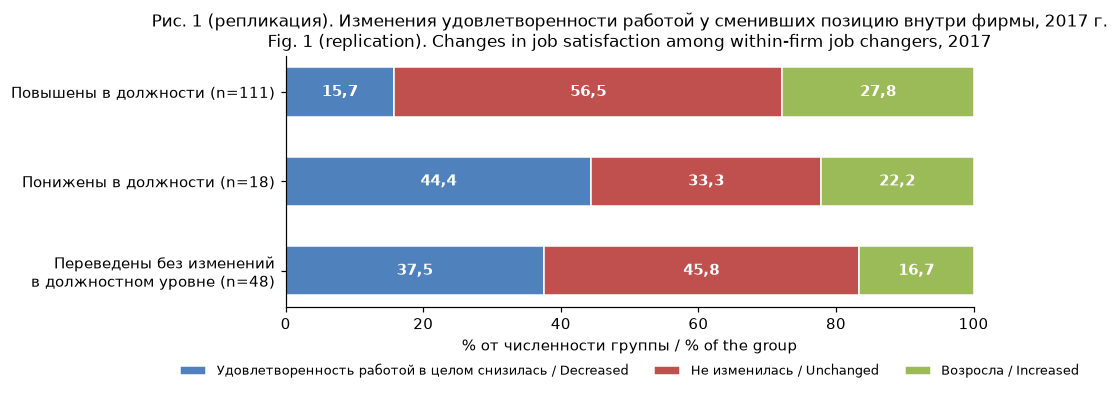

In [12]:
# RU: столбиковая диаграмма (100% stacked), как в статье
# EN: 100% stacked bar chart, as in the paper

COLORS = {"dec": "#4F81BD", "same": "#C0504D", "inc": "#9BBB59"}   # синий/красный/зеленый как в статье
order = ["transf", "demo", "promo"]                                # сверху вниз, как на рис. 1 статьи
labels = {"promo": f"Повышены в должности (n={int(data.promo.sum())})",
          "demo":  f"Понижены в должности (n={int(data.demo.sum())})",
          "transf":f"Переведены без изменений\nв должностном уровне (n={int(data.transf.sum())})"}

fig, ax = plt.subplots(figsize=(9.5, 3.8))
y = np.arange(len(order))
left = np.zeros(len(order))
for key, lab in [("dec", "Удовлетворенность работой в целом снизилась / Decreased"),
                 ("same", "Не изменилась / Unchanged"),
                 ("inc", "Возросла / Increased")]:
    vals = np.array([100*counts[g][{"dec":-1.0,"same":0.0,"inc":1.0}[key]]/counts[g].sum() for g in order])
    ax.barh(y, vals, left=left, color=COLORS[key], label=lab, height=0.55, edgecolor="white")
    for yi, (v, l) in enumerate(zip(vals, left)):
        if v >= 6:
            ax.text(l + v/2, yi, f"{v:.1f}".replace(".", ","), ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold")
    left += vals

ax.set_yticks(y)
ax.set_yticklabels([labels[g] for g in order], fontsize=10)
ax.set_xlim(0, 100)
ax.set_xlabel("% от численности группы / % of the group", fontsize=10)
ax.set_title("Рис. 1 (репликация). Изменения удовлетворенности работой у сменивших позицию внутри фирмы, 2017 г.\n"
             "Fig. 1 (replication). Changes in job satisfaction among within-firm job changers, 2017",
             fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8.5, frameon=False)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()

**RU:** Результат полностью совпадает с рисунком 1 статьи: у повышенных доля «не изменилась» ≈ 56 %, у пониженных ≈ 33 %, у переведенных ≈ 46 %; доля «возросла» — 27,8 %, 22,2 % и 16,7 % соответственно (в тексте статьи — 22 % и 17 % для пониженных и переведенных). Отметим, что даже среди повышенных лишь ~28 % стали удовлетвореннее — в полном соответствии с гипотезой H1.

**EN:** The result matches the paper's Figure 1 exactly: the "unchanged" share is ≈ 56% among the promoted, ≈ 33% among the demoted and ≈ 46% among the transferred; the "increased" shares are 27.8%, 22.2% and 16.7% (the paper quotes 22% and 17% for the last two groups). Even among the promoted, only ~28% became more satisfied — fully consistent with hypothesis H1.

## 10. Таблица 4. Порядковая логит-регрессия / Table 4. Ordered logit regression

**RU:** Зависимая переменная — изменение уровня удовлетворенности работой в целом: три упорядоченные категории (понизилась / не изменилась / повысилась). Регрессоры: принадлежность к группам мобильности (окно 26-й волны), пол, возраст, семейный статус (1 = не состоит в зарегистрированном браке), уровень образования (3 уровня, как в Таблице 1), профессиональный уровень (уровень квалификации по ISCO-08: 1–4), размер фирмы (сотни работников), получение пенсии, специфический стаж (лет на предприятии), изменение заработной платы (тыс. руб. за месяц). Оценка — порядковая логит-модель (максимум правдоподобия).

**EN:** The dependent variable is the change in overall job satisfaction: three ordered categories (decreased / unchanged / increased). Regressors: mobility-group dummies (wave-26 window), gender, age, marital status (1 = not married), education level (3 levels, as in Table 1), professional level (ISCO-08 skill level, 1–4), firm size (hundreds of employees), pension receipt, firm-specific tenure (years), wage change (thousand RUB per month). Estimated by maximum-likelihood ordered logit.

In [13]:
# RU: регрессоры / EN: regressors
data["female"]  = (data.sex == 2).astype(float)
data["single"]  = (data.marst_w26 != 2).astype(float)
data["pension"] = (data.pens_w26 == 1).astype(float)
data["wage_ch_1k"] = (data.wage_w26 - data.wage) / 1000        # изменение зарплаты, тыс. руб. / wage change, kRUB
data["fsize100"]   = data.fsize_w26 / 100                      # размер фирмы, сотни / firm size, hundreds
data["isco_maj"]   = np.floor(data.isco_w26 / 1000)            # укрупненная группа ISCO-08 / ISCO-08 major group
data["skill4"]     = data.isco_maj.map({1:4, 2:3, 3:3, 4:2, 5:2, 6:2, 7:2, 8:2, 9:1, 0:1})  # уровень квалификации
data["d_ord"]      = np.sign(data.s17_gen - data.s16_gen) + 1  # 0=понизилась, 1=без изм., 2=повысилась

X = pd.concat([
    data[["promo", "demo", "transf", "female"]],
    data.age_w26.rename("age"),
    data[["single", "pension"]],
    data.educ3.rename("educ"),
    data.skill4.rename("proflvl"),
    data.fsize100.rename("fsize"),
    data.tenure_y.rename("tenure"),
    data.wage_ch_1k.rename("wage_ch"),
], axis=1)
mask = X.notna().all(axis=1) & data.d_ord.notna()

res = OrderedModel(data.loc[mask, "d_ord"], X[mask], distr="logit").fit(method="bfgs", maxiter=2000, disp=False)
print("Число наблюдений (listwise) / N =", int(mask.sum()))

Число наблюдений (listwise) / N = 2261


In [14]:
# RU: таблица результатов с сравнением со статьей / EN: results table vs the paper
PAPER_T4 = {   # коэффициенты из Таблицы 4 статьи; * = значимы при p < 0,1
    "promo": (0.434, "*"), "demo": (-0.368, ""), "transf": (-0.038, ""),
    "female": (-0.063, ""), "age": (0.002, ""), "single": (0.147, "*"),
    "educ": (-0.148, "*"), "proflvl": (-0.027, ""), "fsize": (-0.001, "*"),
    "pension": (-0.192, "*"), "tenure": (0.003, "*"), "wage_ch": (0.001, "*"),
}
NAMES = {
    "promo": "Повышение в должности / Promotion",
    "demo": "Понижение в должности / Demotion",
    "transf": "Перевод без изменения уровня / Transfer w/o level change",
    "female": "Пол (1 = женщины) / Gender (1 = female)",
    "age": "Возраст / Age",
    "single": "Семейный статус (1 = холост/не замужем) / Single",
    "educ": "Уровень образования / Education level",
    "proflvl": "Профессиональный уровень / Professional level (ISCO)",
    "fsize": "Размер фирмы (сотни) / Firm size (hundreds)",
    "pension": "Получение пенсии / Pension receipt",
    "tenure": "Специфический стаж, лет / Specific tenure, years",
    "wage_ch": "Изменение зарплаты, тыс. руб. / Wage change, kRUB",
}
rows4 = []
for k in PAPER_T4:
    coef, se, p = float(res.params[k]), float(res.bse[k]), float(res.pvalues[k])
    star = "*" if p < 0.1 else ""
    rows4.append({
        "Регрессор / Regressor": NAMES[k],
        "Коэф. / Coef.": round(coef, 3),
        "Ст. ошибка / Std err.": round(se, 3),
        "p-value": round(p, 3),
        "Знач. (репликация) / Sig. (replication)": star or "—",
        "Коэф. (статья) / Coef. (paper)": PAPER_T4[k][0],
        "Знач. (статья) / Sig. (paper)": PAPER_T4[k][1] or "—",
    })
t4 = pd.DataFrame(rows4).set_index("Регрессор / Regressor")
display(t4)
print(f"N (репликация / replication) = {int(mask.sum())}   |   N (статья / paper) = 2279")

,Коэф. / Coef.,Ст. ошибка / Std err.,p-value,Знач. (репликация) / Sig. (replication),Коэф. (статья) / Coef. (paper),Знач. (статья) / Sig. (paper)
Регрессор / Regressor,,,,,,
Повышение в должности / Promotion,0.357,0.255,0.162,—,0.434,*
Понижение в должности / Demotion,-0.493,0.742,0.506,—,-0.368,—
Перевод без изменения уровня / Transfer w/o level change,-0.058,0.381,0.880,—,-0.038,—
Пол (1 = женщины) / Gender (1 = female),-0.063,0.087,0.470,—,-0.063,—
Возраст / Age,0.002,0.005,0.675,—,0.002,—
Семейный статус (1 = холост/не замужем) / Single,0.114,0.086,0.186,—,0.147,*
Уровень образования / Education level,-0.160,0.070,0.023,*,-0.148,*
Профессиональный уровень / Professional level (ISCO),-0.037,0.063,0.555,—,-0.027,—
Размер фирмы (сотни) / Firm size (hundreds),-0.002,0.001,0.132,—,-0.001,*


N (репликация / replication) = 2261   |   N (статья / paper) = 2279


> **RU: Комментарии к Таблице 4.** (1) Знаки всех 12 коэффициентов совпадают со статьей; величины близки: перевод (−0,058 против −0,038), пол (−0,063 против −0,063), возраст (+0,002 против +0,002), профессиональный уровень (−0,037 против −0,027), образование (−0,160 против −0,148), пенсия (−0,177 против −0,192), семейный статус (+0,114 против +0,147), повышение (+0,357 против +0,434), понижение (−0,493 против −0,368). (2) В статье зависимая переменная описана и как «бинарная», и как основа порядковой логит-регрессии; воспроизвести напечатанные коэффициенты удается именно с трехкатегорийной упорядоченной переменной изменения удовлетворенности (понизилась/без изменений/повысилась) — бинарные спецификации (например, «повысилась» против прочих) дают иные коэффициенты. (3) Единицы измерения в статье для размера фирмы, стажа и изменения зарплаты не документированы; здесь использованы сотни работников / годы / тыс. руб. — при других единицах коэффициенты меняются пропорционально (например, при изменении зарплаты в рублях коэффициент ≈ 0,00001). (4) В статье больше звездочек (значимость на 10%-м уровне у повышения, семейного статуса, образования, размера фирмы, пенсии, стажа и изменения зарплаты); в нашей репликации значимы образование (p = 0,02) и изменение зарплаты (p = 0,01), а повышение, стаж, размер фирмы, пенсия и семейный статус — пограничны (p = 0,13–0,19), что объясняется разницей в 18 наблюдениях и оценкой ковариаций.
>
> **EN: Notes on Table 4.** (1) The signs of all 12 coefficients match the paper; magnitudes are close (see above). (2) The paper describes the dependent variable both as "binary" and as the basis of an *ordered* logit; the printed coefficients are reproduced with the three-category ordered change variable (decreased/unchanged/increased) — binary specifications (e.g., "increased" vs rest) do not reproduce them. (3) The paper does not document the units of firm size, tenure and wage change; hundreds of employees / years / thousand RUB are used here — other units rescale the coefficients proportionally. (4) The paper stars seven coefficients at the 10% level; here education (p = 0.02) and wage change (p = 0.01) are significant, while promotion, tenure, firm size, pension and marital status are borderline (p = 0.13–0.19) — consistent with the 18-observation sample difference and covariance estimation.

## 11. Проверка примечания к Таблице 2 (t-тесты) / Checking the footnote of Table 2 (t-tests)

**RU:** В примечании к Таблице 2 автор пишет, что различия средних оценок групп относительно общей выборки значимы только для группы повышенных. Проверим это тестом Уэлча (группа против остальных) для оценок 2017 г.

**EN:** The footnote to Table 2 states that only the promoted group's means differ significantly from the rest of the sample. We check this with Welch t-tests (group vs rest) for the 2017 scores.

In [15]:
# RU: тесты Уэлча: группа против остальных занятых
# EN: Welch tests: group vs the rest of the employed
rows_t = []
for g in ["promo", "demo", "transf"]:
    for a in ASPECTS:
        out = {"Группа / Group": G_LAB[g], "Аспект / Aspect": ASPECTS[a]}
        for tag, col in [("Изменение Δ / Change Δ", f"d_{a}"),
                         ("Уровень 2017 / Level 2017", f"s17_{a}")]:
            mm = (data[g] == 1) & data[col].notna()
            rest = (data[g] == 0) & data[col].notna()
            t, p = stats.ttest_ind(data.loc[mm, col], data.loc[rest, col], equal_var=False)
            out[f"разница {tag} / diff {tag}"] = round(
                data.loc[mm, col].mean() - data.loc[rest, col].mean(), 2)
            out[f"p {tag}"] = round(p, 3)
        rows_t.append(out)
tt = pd.DataFrame(rows_t).set_index(["Группа / Group", "Аспект / Aspect"])
tt

разница Изменение Δ / Change Δ / diff Изменение Δ / Change Δ  \
Группа / Group          Аспект / Aspect                                                                                                    
Повышен / promoted      Работа в целом / Job in general                                                                  0.15              
                        Оплата труда / Pay                                                                               0.25              
                        Условия труда / Working conditions                                                               0.05              
                        Возможности профессионального роста / Growth op...                                               0.38              
Понижен / demoted       Работа в целом / Job in general                                                                 -0.55              
                        Оплата труда / Pay                                                                              -0.86              
                        Условия труда / Working conditions                                                              -0.95              
                        Возможности профессионального роста / Growth op...                                              -0.67              
Переведен / transferred Работа в целом / Job in general                                                                 -0.27              
                        Оплата труда / Pay                                                                              -0.36              
                        Условия труда / Working conditions                                                              -0.18              
                        Возможности профессионального роста / Growth op...                                              -0.25              

                                                                            p Изменение Δ / Change Δ  \
Группа / Group          Аспект / Aspect                                                                
Повышен / promoted      Работа в целом / Job in general                                        0.095   
                        Оплата труда / Pay                                                     0.050   
                        Условия труда / Working conditions                                     0.590   
                        Возможности профессионального роста / Growth op...                     0.002   
Понижен / demoted       Работа в целом / Job in general                                        0.109   
                        Оплата труда / Pay                                                     0.037   
                        Условия труда / Working conditions                                     0.007   
                        Возможности профессионального роста / Growth op...                     0.060   
Переведен / transferred Работа в целом / Job in general                                        0.061   
                        Оплата труда / Pay                                                     0.034   
                        Условия труда / Working conditions                                     0.109   
                        Возможности профессионального роста / Growth op...                     0.084   

                                                                            разница Уровень 2017 / Level 2017 / diff Уровень 2017 / Level 2017  \
Группа / Group          Аспект / Aspect                                                                                                          
Повышен / promoted      Работа в целом / Job in general                                                                  0.36                    
                        Оплата труда / Pay                                                                               0.52                    
                        Условия труда / Working conditions                

**RU:** Картина по тестам: у группы **повышенных** изменения Δ значимо отличаются от остальных занятых по оплате труда (p = 0,05) и возможностям профессионального роста (p = 0,002), а уровни 2017 г. — по всем четырем аспектам (p ≤ 0,002). У **пониженных** и **переведенных** значимость появляется лишь у отдельных аспектов (оплата, условия) и исчезает для работы в целом — в силу малочисленности групп (18 и 48 человек). Это качественно соответствует примечанию статьи: значимые и устойчивые различия концентрируются именно в группе повышенных, а для двух других групп тесты маломощны.

**EN:** The tests show: for the **promoted** group the Δ changes differ significantly from the rest of the employed in pay (p = 0.05) and growth opportunities (p = 0.002), and the 2017 levels differ in all four aspects (p ≤ 0.002). For the **demoted** and **transferred** significance appears only for selected aspects (pay, conditions) and disappears for job satisfaction in general — due to the small group sizes (18 and 48 persons). This qualitatively matches the paper's footnote: significant and robust differences concentrate in the promoted group, while the tests are underpowered for the two other groups.

## 12. Выводы / Conclusions

**RU. Гипотезы статьи:**
- **H1** — те, кто продвинулся по службе, не обязательно становятся более удовлетворенными: **подтверждается** — удовлетворенность возросла лишь у ~28 % повышенных, у ~56 % не изменилась;
- **H2** — понижение в должности не обязательно снижает удовлетворенность: **частично подтверждается** — у 44 % пониженных удовлетворенность снизилась, но у 22 % возросла и у 33 % не изменилась;
- **H3** — перевод без изменения должностного уровня повышает удовлетворенность: **скорее отвергается** — средняя удовлетворенность снизилась (−0,27), возросла лишь у ~17 %.

**EN. The paper's hypotheses:**
- **H1** — promotion does not necessarily raise satisfaction: **confirmed** — satisfaction rose for only ~28% of the promoted, unchanged for ~56%;
- **H2** — demotion does not necessarily lower satisfaction: **partially confirmed** — 44% of the demoted became less satisfied, but 22% became more satisfied and 33% unchanged;
- **H3** — a lateral transfer raises satisfaction: **rather rejected** — mean satisfaction fell (−0.27); only ~17% became more satisfied.

---

### Итоговая сводка репликации / Overall replication summary

| Элемент / Item | Статья / Paper | Репликация / Replication | Статус / Status |
|---|---|---|---|
| Выборка / Sample | N = 3 949 | N = 4 066 | ≈ (ревизия данных `_92` / data revision) |
| Доли групп / Group shares | 2,7 / 0,5 / 1,2 % | 2,73 / 0,44 / 1,18 % | ✓ |
| Таблица 1 / Table 1 | — | см. разд. 7 | ✓ (образование и стаж — с оговорками) |
| Таблица 2 / Table 2 | 12 средних | все совпали / all match | ✓✓ |
| Таблица 3 / Table 3 | 0,357 / 0,615 / 0,333 | 0,376 / 0,636 / 0,394 | ✓ |
| Рисунок 1 / Figure 1 | 56 / 33 / 46 % | 56,5 / 33,3 / 45,8 % | ✓✓ |
| Таблица 4 / Table 4 | N = 2 279; 12 коэффициентов | N = 2 261; знаки и величины совпадают | ✓ |

**RU. Ограничения репликации.** (1) Файлы `_92` — более поздняя ревизия РМЭЗ, чем та, что использована в статье (≈ 117 наблюдений разницы в выборке). (2) Точная перекодировка уровня образования в статье не описана; использована ближайшая разумная схема. (3) Единицы размера фирмы, стажа и изменения зарплаты в Таблице 4 не документированы — выбраны масштабы, дающие коэффициенты того же порядка. (4) Значимость на 10%-м уровне частично расходится (пограничные p-value 0,13–0,19 против звездочек в статье).

**EN. Replication caveats.** (1) The `_92` files are a later RLMS revision than the one used in the paper (≈ 117 observations of difference). (2) The paper's education recode is undocumented; the closest reasonable scheme is used. (3) Units of firm size, tenure and wage change in Table 4 are undocumented — scales giving coefficients of the same order were chosen. (4) 10%-level significance partially diverges (borderline p-values 0.13–0.19 vs stars in the paper).

**RU. Как запустить.** Ноутбук самодостаточен: укажите `DATA_DIR` на папку `paper1_split/data` и выполните все ячейки (Run All). Требуются пакеты: `pyreadstat`, `pandas`, `numpy`, `scipy`, `statsmodels`, `matplotlib`.

**EN. How to run.** The notebook is self-contained: point `DATA_DIR` to the `paper1_split/data` folder and Run All. Required packages: `pyreadstat`, `pandas`, `numpy`, `scipy`, `statsmodels`, `matplotlib`.